# Two MX Weight Precisions — SVHN / CNN-8

This notebook contains two presentation figures:

1. **Accuracy:** dedicated QAT, joint direct QAT, post-training mantissa truncation, and joint truncation-aware training, shown in separate MXFP6 and MXFP4 panels.
2. **Persistent model storage:** two dedicated models, one MXFP6 source from joint QAT with post-training truncation, and one MXFP6 source from truncation-aware training. Both joint cases support MXFP4 by mantissa truncation.

All data needed for these figures are embedded below. **Run All** recreates both figures and writes PNG (300 dpi), SVG, CSV and JSON exports into `figures/`. The only third-party dependency is Matplotlib. No training, dataset download or model evaluation is performed.

The figures use English headings, percentage labels, and no explanatory footer. The methodology and source details remain in the notebook.


## 1. Experiment settings and measurement policy

| Setting | Value |
|:--|:--|
| Dataset / model | SVHN / CNN-8 (`svhnq`, `expand=2`) |
| Weight formats | MXFP6 E2M3 and MXFP4 E2M1 |
| Activations | FP32 (A32) |
| MX group size / scale format | 32 / E8M0 |
| Training | 100 epochs, fresh initialization for each training trajectory |
| Optimizer / initial learning rate | Adam / 0.001 |
| Learning-rate schedule | Multiply by 0.1 after epochs 50, 75 and 90 |
| Batch size | 128 |
| Weight decay / dropout | 0 / 0.5 |
| Distillation | Joint models only; MXFP6 teaches MXFP4 |
| Master weights during training | FP32 |
| Seed / repetitions | 20261009 / one run per trajectory |

Dedicated QAT uses one hard-label cross-entropy pass per minibatch. Joint training uses two precision passes, high-mode hard cross-entropy and low-mode soft cross-entropy from the detached high-mode teacher, temperature 1, summed gradients and one optimizer update. The dedicated and joint training objectives and compute budgets therefore differ.

The training rows preserve the original logged test accuracies at the final checkpoint (epoch 100). They are not best-checkpoint scores. The post-training-truncation row comes from a separate evaluation of the same joint-direct final checkpoint, with zero optimizer steps and no BatchNorm recalibration. Original training results are not replaced by later re-evaluations. No error bars are shown because these are individual runs.

Dropout 0.5 is the setting in the common CNN-8 architecture source. Dataset split and full per-run configuration remain in the embedded provenance; they are not added to the figure headers.


In [1]:
import csv
import io
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator


In [2]:
DATA = json.loads(r'''
{
  "schema": "mx-two-precision-midterm-v2",
  "dataset": "SVHN",
  "model": "CNN-8",
  "model_factory": "models.svhn_quan.svhnq",
  "training": {
    "epochs": 100,
    "optimizer": "Adam",
    "initial_lr": 0.001,
    "batch_size": 128,
    "lr_milestones": [
      50,
      75,
      90
    ],
    "lr_decay_factor": 0.1,
    "weight_decay": 0.0,
    "dropout_probability": 0.5,
    "activation_bits": 32,
    "group_size": 32,
    "scale_format": "E8M0",
    "distillation": "Recursive knowledge distillation: joint models only",
    "seed": 20261009,
    "master_dtype_during_training": "float32",
    "common_run_configuration": {
      "planned_epochs": 100,
      "optimizer": "adam",
      "lr": 0.001,
      "batch_size": 128,
      "scheduler_milestones": [
        50,
        75,
        90
      ],
      "scheduler_gamma": 0.1,
      "weight_decay": 0.0,
      "activation_bits": 32,
      "mx_block_size": 32,
      "mx_scale_format": "E8M0",
      "master_dtype": "float32",
      "seed": 20261009,
      "expand": 2
    }
  },
  "accuracy": [
    {
      "id": "dedicated",
      "label": "Dedicated QAT \u2014 separate models",
      "values": {
        "E2M3": {
          "accuracy_percent": 94.82559925775698,
          "correct": 24685,
          "n": 26032,
          "training_id": "dedicated_mxfp6",
          "run_id": "20261017_190413_551517_mx_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "e276bea6a3c9a6716a88535800b383fe35de6d77c3d6925a4cadaa0b24e411d1"
        },
        "E2M1": {
          "accuracy_percent": 94.82175783650891,
          "correct": 24684,
          "n": 26032,
          "training_id": "dedicated_mxfp4",
          "run_id": "20261021_182608_167996_mx_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "81d92fff125392a55c7de83a711411d16596f2aff3d26babc8986e176bf02e4a"
        }
      }
    },
    {
      "id": "joint_direct",
      "label": "Joint QAT \u2014 direct quantization",
      "values": {
        "E2M3": {
          "accuracy_percent": 95.03303625368237,
          "correct": 24739,
          "n": 26032,
          "training_id": "dual_direct",
          "run_id": "20261019_192538_709626_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "9542d282201da6483b7b56e0f15619e53a78ca1ceae6c00c80e7f74f4c9fd9b5"
        },
        "E2M1": {
          "accuracy_percent": 95.02535340180775,
          "correct": 24737,
          "n": 26032,
          "training_id": "dual_direct",
          "run_id": "20261019_192538_709626_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "9542d282201da6483b7b56e0f15619e53a78ca1ceae6c00c80e7f74f4c9fd9b5"
        }
      }
    },
    {
      "id": "post_training_truncation",
      "label": "Joint QAT + post-training mantissa truncation",
      "values": {
        "E2M3": {
          "accuracy_percent": 95.03303626306085,
          "correct": 24739,
          "n": 26032,
          "training_id": "dual_direct",
          "measurement_kind": "native_evaluation",
          "epoch": 100,
          "case_id": "dual_mantissa__dual_direct__last_epoch__H_source_E2M3",
          "evaluation_run_id": "20261020_173705_352283_evaluate",
          "checkpoint_sha256": "9542d282201da6483b7b56e0f15619e53a78ca1ceae6c00c80e7f74f4c9fd9b5",
          "optimizer_steps": 0,
          "batchnorm_recalibrated": false
        },
        "E2M1": {
          "accuracy_percent": 93.58097725875845,
          "correct": 24361,
          "n": 26032,
          "training_id": "dual_direct",
          "measurement_kind": "posthoc_conversion",
          "epoch": 100,
          "case_id": "dual_mantissa__dual_direct__last_epoch__C_truncate_E2M3",
          "evaluation_run_id": "20261020_173705_352283_evaluate",
          "checkpoint_sha256": "9542d282201da6483b7b56e0f15619e53a78ca1ceae6c00c80e7f74f4c9fd9b5",
          "optimizer_steps": 0,
          "batchnorm_recalibrated": false
        }
      }
    },
    {
      "id": "joint_truncation",
      "label": "Joint truncation-aware training",
      "values": {
        "E2M3": {
          "accuracy_percent": 94.9638905961893,
          "correct": 24721,
          "n": 26032,
          "training_id": "dual_mantissa",
          "run_id": "20261021_153559_999222_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "0bb0e0e0cd83a05e1adafecb8e95af2d58985166268a2fbc239e8e607cdcd036"
        },
        "E2M1": {
          "accuracy_percent": 94.94084204056546,
          "correct": 24715,
          "n": 26032,
          "training_id": "dual_mantissa",
          "run_id": "20261021_153559_999222_joint_run",
          "measurement_kind": "original training record",
          "epoch": 100,
          "checkpoint_sha256": "0bb0e0e0cd83a05e1adafecb8e95af2d58985166268a2fbc239e8e607cdcd036"
        }
      }
    }
  ],
  "storage": [
    {
      "id": "dual_dedicated_separate",
      "label": "Dedicated models",
      "representation": "Two packed models: MXFP6 + MXFP4",
      "code_bytes": 163200,
      "scale_bytes": 8160,
      "retained_state_bytes": 38496,
      "total_bytes": 209856,
      "auxiliary_copies": 2,
      "implementation": "existing_separate_exports",
      "accuracy_method_id": "dedicated"
    },
    {
      "id": "dual_direct_posthoc_source",
      "label": "Joint QAT + post-training truncation",
      "representation": "One MXFP6 source; MXFP4 by post-training mantissa truncation",
      "code_bytes": 97920,
      "scale_bytes": 4080,
      "retained_state_bytes": 19248,
      "total_bytes": 121248,
      "auxiliary_copies": 1,
      "implementation": "existing_joint_direct_MXFP6_source_with_post_training_mantissa_truncation",
      "accuracy_method_id": "post_training_truncation"
    },
    {
      "id": "dual_mantissa_source",
      "label": "Joint truncation-aware training",
      "representation": "One MXFP6 source; MXFP4 by mantissa truncation",
      "code_bytes": 97920,
      "scale_bytes": 4080,
      "retained_state_bytes": 19248,
      "total_bytes": 121248,
      "auxiliary_copies": 1,
      "implementation": "existing_truncatable_source_export",
      "accuracy_method_id": "joint_truncation"
    }
  ],
  "source_only_evaluation": [
    {
      "accuracy_percent": 94.96773202212661,
      "correct": 24722,
      "n": 26032,
      "training_id": "dual_mantissa",
      "measurement_kind": "source_export_evaluation",
      "epoch": 100,
      "case_id": "dual_source_only__dual_truncation__last_epoch__E2M3_source_only",
      "evaluation_run_id": "20261021_200641_799256_evaluate",
      "checkpoint_sha256": "0bb0e0e0cd83a05e1adafecb8e95af2d58985166268a2fbc239e8e607cdcd036",
      "optimizer_steps": 0,
      "batchnorm_recalibrated": false
    },
    {
      "accuracy_percent": 94.94468346650277,
      "correct": 24716,
      "n": 26032,
      "training_id": "dual_mantissa",
      "measurement_kind": "source_export_evaluation",
      "epoch": 100,
      "case_id": "dual_source_only__dual_truncation__last_epoch__E2M1_source_only",
      "evaluation_run_id": "20261021_200641_799256_evaluate",
      "checkpoint_sha256": "0bb0e0e0cd83a05e1adafecb8e95af2d58985166268a2fbc239e8e607cdcd036",
      "optimizer_steps": 0,
      "batchnorm_recalibrated": false
    }
  ],
  "round_from_mxfp6_control": {
    "accuracy_percent": 94.45298094652735,
    "correct": 24588,
    "n": 26032,
    "training_id": "dual_direct",
    "measurement_kind": "posthoc_conversion",
    "epoch": 100,
    "case_id": "dual_mantissa__dual_direct__last_epoch__B_round_from_E2M3",
    "evaluation_run_id": "20261020_173705_352283_evaluate",
    "checkpoint_sha256": "9542d282201da6483b7b56e0f15619e53a78ca1ceae6c00c80e7f74f4c9fd9b5",
    "optimizer_steps": 0,
    "batchnorm_recalibrated": false
  },
  "storage_accounting": {
    "target_weight_count": 129472,
    "group_count": 4080,
    "stored_slots": 130560,
    "padding_slots": 1088,
    "group_size": 32,
    "fp32_first_last_bytes_per_export": 8808,
    "batchnorm_bytes_per_export_all_five_banks": 10440,
    "retained_state_bytes_per_export": 19248,
    "mxfp6_code_bytes": 97920,
    "mxfp4_code_bytes": 65280,
    "scale_bytes_per_representation": 4080,
    "source_only_total_bytes": 121248,
    "two_export_total_bytes": 209856,
    "scope": "Logical persistent payload supporting both modes. Dedicated uses two packed models; both joint cases use one MXFP6 source with mantissa truncation. Includes padding, E8M0 scales and retained model state; excludes optimizer state, activations, temporary buffers and file-container overhead."
  },
  "provenance": {
    "source_notebook": "MX_onderzoeksoverzicht_meeting_20261029.ipynb",
    "source_notebook_library_id": "libfile_6fcbc29932c88191b47bf7be6a45d2f1",
    "decoded_source_sha256": "145471897ecfb37c5741e076c213d674e1e1920a29c7fb1077e39a94ccdefd83",
    "training_sources": {
      "dedicated_mxfp6": {
        "run_id": "20261017_190413_551517_mx_run",
        "source": {
          "bundle_name": "feedback_bundle(9).zip",
          "zip_sha256": "a9a3cf057abc0957778259e0e960538921d89f74e4f953868ca569655f1c1f9d",
          "metrics_path": "sources/training/dedicated_mxfp6/epoch_metrics.csv",
          "metrics_sha256": "fc96fcb071fbb4fe480d88995310dadeda8eb619a3f428bd0b25a2bf870f33ea",
          "report_path": "sources/training/dedicated_mxfp6/run_report.json",
          "report_sha256": "e9cbbc16f4168c3ebb6de0f1c7bf1162b913c81de1934a969ed87f22874ad872",
          "selection_path": "sources/training/dedicated_mxfp6/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dedicated_mxfp6/selected_metrics.csv",
          "epoch_times_path": "sources/training/dedicated_mxfp6/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 1,
          "optimizer_steps_per_training_batch": 1,
          "distillation": false,
          "truncation": false,
          "selection_policy": "first strict maximum of active-mode official-test top1",
          "loss": "hard-label CrossEntropyLoss, mean reduction"
        }
      },
      "dedicated_mxfp4": {
        "run_id": "20261021_182608_167996_mx_run",
        "source": {
          "bundle_name": "feedback_bundle(20261021-171049).zip",
          "zip_sha256": "951f865bc08883bbe88cbe8d14b76a2f612a454b6cef058e15f3a9784b13dc86",
          "metrics_path": "sources/training/dedicated_mxfp4/epoch_metrics.csv",
          "metrics_sha256": "5e526a4c2633a97e37087802e3212b5a7ecb1d2e0e4612b0154da91172abae00",
          "report_path": "sources/training/dedicated_mxfp4/run_report.json",
          "report_sha256": "9d192214376689a0f39547ddad3162132d997312f3afed74e880acf0677c085d",
          "selection_path": "sources/training/dedicated_mxfp4/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dedicated_mxfp4/selected_metrics.csv",
          "epoch_times_path": "sources/training/dedicated_mxfp4/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 1,
          "optimizer_steps_per_training_batch": 1,
          "distillation": false,
          "truncation": false,
          "selection_policy": "first strict maximum of active-mode official-test top1",
          "loss": "hard-label CrossEntropyLoss, mean reduction"
        }
      },
      "dual_direct": {
        "run_id": "20261019_192538_709626_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261019-184806).zip",
          "zip_sha256": "af632d6966bb5d34464342d9c1f8cb72d94a4f7e5caf5e045a6234eef6a22294",
          "metrics_path": "sources/training/dual_direct/epoch_metrics.csv",
          "metrics_sha256": "8c3b1f07ed92d69f89bdedf72ca3b610c53a2cf11eb72fefb03bdb641ed07dbb",
          "report_path": "sources/training/dual_direct/run_report.json",
          "report_sha256": "a2f95bf189060087fa3a757e06a28bf0fbdf04d6939bfc6bb78f30bc4389652e",
          "selection_path": "sources/training/dual_direct/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dual_direct/selected_metrics.csv",
          "epoch_times_path": "sources/training/dual_direct/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 2,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": false,
          "selection_policy": "first strict maximum of E2M3/A32 official-test top1",
          "loss": "E2M3 hard CE + E2M1 upstream soft CE with detached E2M3 teacher; T=1; no division by 2",
          "training_mode_order": [
            6,
            4
          ],
          "bn_bank_mapping": {
            "6": "32",
            "4": "4"
          }
        }
      },
      "dual_mantissa": {
        "run_id": "20261021_153559_999222_joint_run",
        "source": {
          "bundle_name": "feedback_bundle(20261021-144630).zip",
          "zip_sha256": "a84e609955243a48b96e3a5d4049c6ec13bf171cdc6c8de84432bbb2d3e5bbeb",
          "metrics_path": "sources/training/dual_mantissa/epoch_metrics.csv",
          "metrics_sha256": "bdc13e22203c90ff9b81a8a3b284212cb313a4d5c786c0c63c9ab9cea425c3a7",
          "report_path": "sources/training/dual_mantissa/run_report.json",
          "report_sha256": "8d58e6fb56c8fa49894306cbccbc165b05b5667aafd0d13ea498f82b38ce461c",
          "selection_path": "sources/training/dual_mantissa/checkpoint_selection.json",
          "selected_metrics_path": "sources/training/dual_mantissa/selected_metrics.csv",
          "epoch_times_path": "sources/training/dual_mantissa/epoch_times.csv",
          "metrics_epoch_range": [
            1,
            100
          ]
        },
        "config": {
          "model": "svhnq",
          "expand": 2,
          "dataset": "svhn",
          "train_split": "train",
          "test_split": "test",
          "extra_used": false,
          "train_examples": 73257,
          "test_examples": 26032,
          "validation_examples": 0,
          "parameters": 132954,
          "seed": 20261009,
          "batch_size": 128,
          "optimizer": "adam",
          "lr": 0.001,
          "weight_decay": 0.0,
          "scheduler_milestones": [
            50,
            75,
            90
          ],
          "scheduler_gamma": 0.1,
          "planned_epochs": 100,
          "activation_bits": 32,
          "master_dtype": "float32",
          "gradient_dtype": "float32",
          "adam_moments_dtype": "float32",
          "mx_block_size": 32,
          "mx_scale_format": "E8M0",
          "mx_group_axis": "flatten Cin*Kh*Kw within each Cout, zero-pad tail",
          "passes_per_training_batch": 2,
          "optimizer_steps_per_training_batch": 1,
          "distillation": true,
          "truncation": true,
          "selection_policy": "first strict maximum of E2M3/A32 official-test top1",
          "loss": "E2M3 hard CE + E2M1 upstream soft CE with detached E2M3 teacher; T=1; no division by 2",
          "training_mode_order": [
            6,
            4
          ],
          "bn_bank_mapping": {
            "6": "32",
            "4": "4"
          }
        }
      }
    },
    "dropout_evidence": {
      "source": "Any-Precision-DNNs-master.zip / models/svhn_quan.py",
      "source_sha256": "c891da23c7d2934cd65e3c596c3e47b47de8987385bc8d06eab22de7d2d02e74",
      "setting": "nn.Dropout(0.5) in the common CNN-8 architecture",
      "verification_scope": "Architecture setting; no new inspection of binary models or per-run wrapper code."
    },
    "original_logged_training_metrics_preserved": true,
    "new_training_or_model_evaluation": false,
    "checkpoints_or_binary_exports_loaded": false,
    "storage_calculation_method": "Read-only recomputation from tensor metadata; validated against actual full100 group reports and all full100 export layer CSVs.",
    "joint_qat_single_source": {
      "training_id": "dual_direct",
      "export_file": "mx_direct_MXFP6_E2M3_last.pt",
      "export_sha256": "1e867aa3611ef3429e549857d787f4b3c8c80a58885738410918cf6773fea986",
      "source_report_sha256": "a2f95bf189060087fa3a757e06a28bf0fbdf04d6939bfc6bb78f30bc4389652e",
      "logical_source_bytes": 121248,
      "low_mode_case_id": "dual_mantissa__dual_direct__last_epoch__C_truncate_E2M3",
      "accuracy_figure_row": "post_training_truncation"
    }
  }
}
''')


## 2. Figure settings

The accuracy panels share the same horizontal scale. Each row is a method and each column is an output format. Points are not connected. The range is zoomed to show the observed differences; it can be changed using `ACCURACY_XLIM`.


In [3]:
FIGURE_SIZE = (15.0, 8.0)
EXPORT_DIR = Path('figures')
EXPORT_DPI = 300
ACCURACY_XLIM = (93.0, 96.0)
ACCURACY_XTICKS = [93.0, 93.5, 94.0, 94.5, 95.0, 95.5, 96.0]
LABEL_DECIMALS = 3

NAVY = '#19384B'
MUTED = '#526C7E'
GRID = '#DFE6EC'
SPINE = '#BCCAD4'
ROW_BAND = '#F3F5F7'
MODE_COLORS = {'E2M3': '#3D6789', 'E2M1': '#4C8D80'}
STORAGE_COLORS = ['#25658A', '#73B5AC', '#9BAEBE']

mpl.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 13,
    'text.color': NAVY, 'axes.labelcolor': NAVY,
    'xtick.color': NAVY, 'ytick.color': NAVY,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'svg.fonttype': 'none',
})

def add_heading(fig, training=True):
    fig.text(0.045, 0.945, 'Two MX Weight Precisions', fontsize=25, weight='bold', va='top')
    fig.text(0.045, 0.875, 'Dataset: SVHN  |  Model: CNN-8', fontsize=17, va='top')
    if training:
        t = DATA['training']
        milestones = ', '.join(map(str, t['lr_milestones']))
        lines = [
            f"Epochs: {t['epochs']}  |  {t['optimizer']}  |  Initial LR: {t['initial_lr']:g}  |  Batch size: {t['batch_size']}",
            f"LR milestones: {milestones}  |  LR decay factor: {t['lr_decay_factor']:g}  |  Weight decay: {t['weight_decay']:g}  |  Dropout: {t['dropout_probability']:g}",
            f"Activations: FP32  |  MX group size: {t['group_size']}  |  {t['distillation']}",
        ]
        for y, line in zip([0.813, 0.768, 0.723], lines):
            fig.text(0.045, y, line, fontsize=12.7, color=MUTED, va='top')
    else:
        fig.text(0.045, 0.813, 'MXFP6 · E2M3 / A32  |  MXFP4 · E2M1 / A32', fontsize=16, color=MUTED, va='top')
        fig.text(0.045, 0.764, 'MX group size: 32  |  Persistent model storage for both modes', fontsize=13, color=MUTED, va='top')

def style_axes(ax):
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(SPINE)
        ax.spines[side].set_linewidth(0.9)
    ax.tick_params(length=3, width=0.8, labelsize=12)


## 3. Accuracy comparison

The post-training-truncation row derives MXFP4 by removing the two lowest mantissa bits of the joint-direct model's MXFP6 codes. The block scale is retained and the existing target-mode BatchNorm bank remains frozen. The source MXFP6 mode is unchanged. The low-mode difference therefore includes the changed weight route and its interaction with the previously trained BatchNorm state.


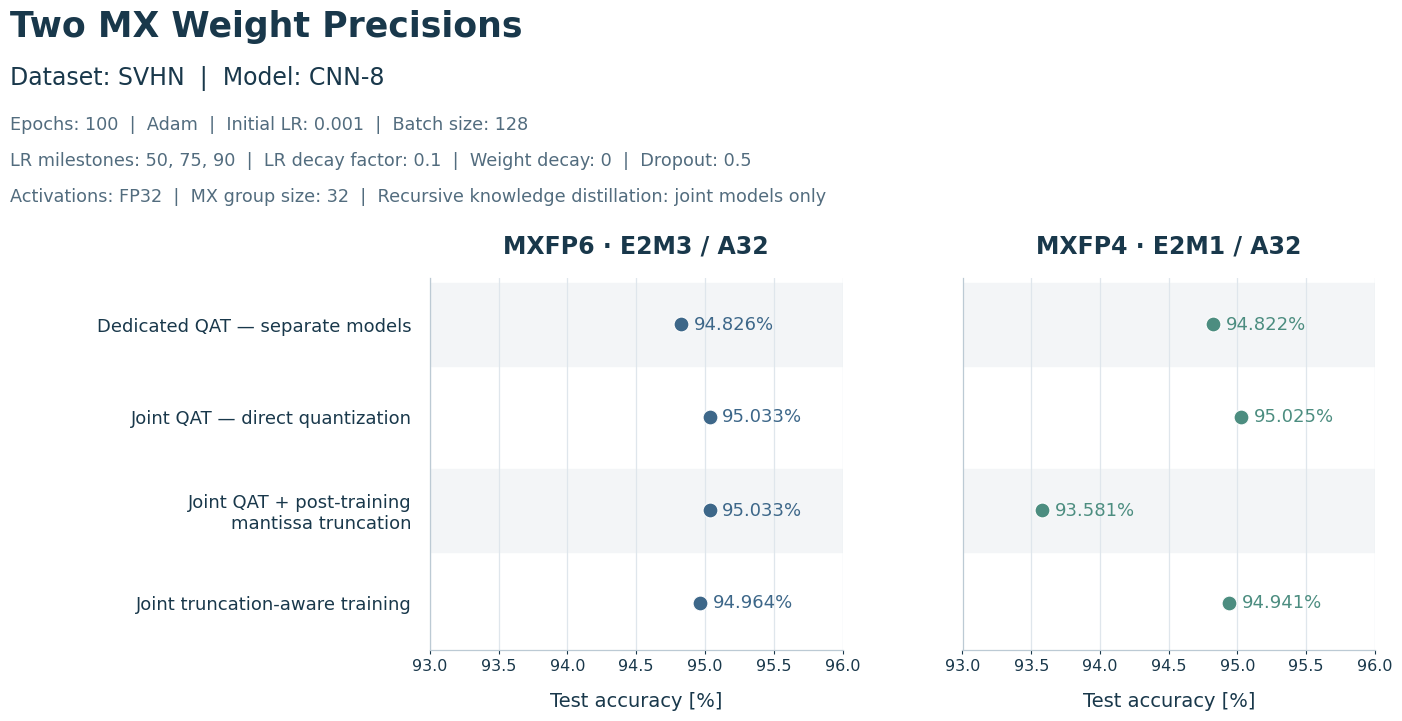

In [4]:
accuracy_rows = DATA['accuracy']
for row in accuracy_rows:
    for mode in ('E2M3', 'E2M1'):
        value = row['values'][mode]
        assert value['epoch'] == 100 and value['n'] == 26032
        assert abs(100 * value['correct'] / value['n'] - value['accuracy_percent']) < 1e-6

method_labels = [
    'Dedicated QAT — separate models',
    'Joint QAT — direct quantization',
    'Joint QAT + post-training\nmantissa truncation',
    'Joint truncation-aware training',
]
fig_accuracy = plt.figure(figsize=FIGURE_SIZE)
add_heading(fig_accuracy, training=True)
accuracy_axes = []
for index, (mode, title, left) in enumerate([
    ('E2M3', 'MXFP6 · E2M3 / A32', 0.325),
    ('E2M1', 'MXFP4 · E2M1 / A32', 0.680),
]):
    ax = fig_accuracy.add_axes([left, 0.145, 0.275, 0.465])
    accuracy_axes.append(ax)
    style_axes(ax)
    for y in [0, 2]:
        ax.axhspan(y - 0.45, y + 0.45, color=ROW_BAND, zorder=0)
    ax.xaxis.grid(True, color=GRID, linewidth=0.9)
    values = [row['values'][mode]['accuracy_percent'] for row in accuracy_rows]
    ax.scatter(values, list(range(4)), s=115, color=MODE_COLORS[mode], edgecolors='white', linewidths=0.8, zorder=3)
    for y, value in enumerate(values):
        ax.annotate(f'{value:.{LABEL_DECIMALS}f}%', (value, y), xytext=(9, 0),
                    textcoords='offset points', ha='left', va='center',
                    fontsize=13, color=MODE_COLORS[mode])
    ax.set_xlim(*ACCURACY_XLIM)
    ax.set_ylim(3.5, -0.5)
    ax.xaxis.set_major_locator(FixedLocator(ACCURACY_XTICKS))
    ax.set_yticks(list(range(4)), method_labels if index == 0 else [''] * 4)
    ax.tick_params(axis='y', length=0, labelsize=13, pad=13)
    ax.tick_params(axis='x', labelsize=11.5)
    ax.set_title(title, fontsize=17, weight='bold', pad=18)
    ax.set_xlabel('Test accuracy [%]', fontsize=14, labelpad=13)
plt.show()


### Values shown

| Method | MXFP6 · E2M3 | MXFP4 · E2M1 |
|:--|--:|--:|
| Dedicated QAT — separate models | 94.826% | 94.822% |
| Joint QAT — direct quantization | 95.033% | 95.025% |
| Joint QAT + post-training mantissa truncation | 95.033% | 93.581% |
| Joint truncation-aware training | 94.964% | 94.941% |

The single MXFP6 conversion of the earlier Any-Precision W32/A32 mode is not included as a fifth row: no corresponding MXFP4 measurement is present, and that parent was already trained using the original multi-precision QAT procedure.


## 4. Which representation must be stored after training?

**Dedicated models:** store the separately trained MXFP6 model and MXFP4 model. Their quantized layers do not require FP32 master copies for inference.

**Joint QAT + post-training mantissa truncation (middle storage bar):** store one MXFP6 source and its block scales, then derive MXFP4 by removing two mantissa bits. This is the third accuracy row, with MXFP4 accuracy 93.581%. It does not require the FP32 master tensors of the MX layers or a separately stored MXFP4 code set.

**The original joint-direct route (second accuracy row):** its two direct quantizations can instead be preserved by retaining a FP32 source or both MX code sets. Its MXFP4 accuracy is 95.025%. This alternative is still shown in the accuracy comparison but is not the middle storage case. Keeping only MXFP6 does not in general preserve that direct MXFP4 result: rounding the saved MXFP6 source to MXFP4 yielded 94.453%, while mantissa truncation yielded 93.581%. These are different inference routes.

**Joint truncation-aware training (last storage bar):** retain one packed MXFP6 source and its E8M0 block scales. The MXFP4 route is derived by removing two mantissa bits with the same scale, as it was during training. No FP32 master copy of the six MX-quantized weight tensors is needed for this inference representation. This is the fourth accuracy row, with the original logged MXFP4 accuracy 94.941%.

The two joint storage cases therefore have the same model payload. Their different training procedures yield different accuracies for the same type of compact inference representation.

Every option retains the FP32 first convolution and final classifier and its BatchNorm state. Runtime activations, decoded temporary tensors and convolution workspaces are additional memory. The inference emulator still computes with floating-point tensors; packed storage does not by itself prove native MX execution or hardware energy savings.

FP32 master weights were used during training for all these runs. Continuing the existing training procedure requires its training state; the compact inference representation and a resumable training checkpoint serve different purposes.


## 5. Storage accounting

The metric is the **logical persistent model payload supporting both output modes**. Dedicated models retain both independently trained MX representations. Each joint case retains one MXFP6 source and derives MXFP4 by mantissa truncation. The metric includes padding, one 8-bit E8M0 scale per block, FP32 first/last layers and retained BatchNorm state. It excludes file-container overhead, optimizer state, gradients, activations and temporary buffers.

The six MX layers contain 129,472 weights. At group size 32 they use 4,080 blocks and 130,560 stored slots, including 1,088 padding slots. Their packed code sizes are 97,920 bytes for MXFP6 and 65,280 bytes for MXFP4; each representation has 4,080 scale bytes.

Each retained model copy contains 19,248 bytes of auxiliary state: 8,808 bytes for the FP32 first/last layers and 10,440 bytes for **all five existing BatchNorm banks**, including counters. No unused-bank pruning is assumed. The dedicated case counts two copies of this state. Each joint case counts one copy, including the target-mode BatchNorm bank used for MXFP4.

The middle case uses the already reported MXFP6 export of the joint-direct model, with the measured post-training mantissa-truncation route. Its shape-derived code, scale and retained-state sizes match the MXFP6 source of the truncation-aware model. The two equal bars mean **equal storage for one MXFP6 source**, while the accuracy figure shows the effect of training with the truncation route. The middle storage bar must be read together with the third accuracy row, not with the direct-quantization result in the second row.


In [5]:
accounting = DATA['storage_accounting']
assert accounting['stored_slots'] == accounting['group_count'] * accounting['group_size']
assert accounting['stored_slots'] - accounting['target_weight_count'] == accounting['padding_slots']
assert accounting['stored_slots'] * 6 // 8 == accounting['mxfp6_code_bytes']
assert accounting['stored_slots'] * 4 // 8 == accounting['mxfp4_code_bytes']
assert accounting['fp32_first_last_bytes_per_export'] + accounting['batchnorm_bytes_per_export_all_five_banks'] == accounting['retained_state_bytes_per_export']

storage_rows = DATA['storage']
for row in storage_rows:
    assert row['code_bytes'] + row['scale_bytes'] + row['retained_state_bytes'] == row['total_bytes']
assert [r['total_bytes'] for r in storage_rows] == [209856, 121248, 121248]

for row in storage_rows:
    print(f"{row['label']}: {row['total_bytes']:,} bytes = {row['total_bytes'] / 1024:.6f} KiB")


Dedicated models: 209,856 bytes = 204.937500 KiB
Joint QAT + post-training truncation: 121,248 bytes = 118.406250 KiB
Joint truncation-aware training: 121,248 bytes = 118.406250 KiB


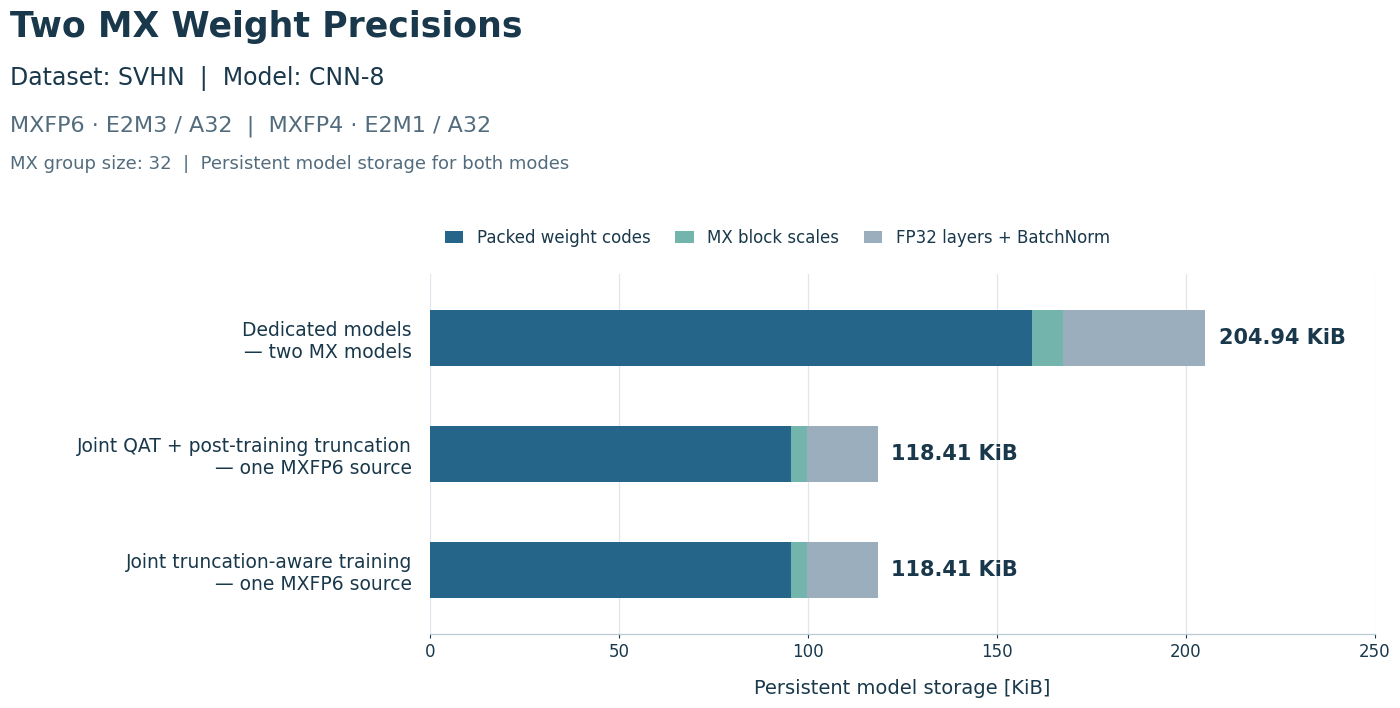

In [6]:
fig_storage = plt.figure(figsize=FIGURE_SIZE)
add_heading(fig_storage, training=False)
ax_storage = fig_storage.add_axes([0.325, 0.165, 0.630, 0.450])
style_axes(ax_storage)
ax_storage.spines['left'].set_visible(False)
ax_storage.xaxis.grid(True, color=GRID, linewidth=0.9)

component_fields = ['code_bytes', 'scale_bytes', 'retained_state_bytes']
component_labels = ['Packed weight codes', 'MX block scales', 'FP32 layers + BatchNorm']
storage_labels = [
    'Dedicated models\n— two MX models',
    'Joint QAT + post-training truncation\n— one MXFP6 source',
    'Joint truncation-aware training\n— one MXFP6 source',
]
for y, row in enumerate(storage_rows):
    left = 0.0
    for field, color in zip(component_fields, STORAGE_COLORS):
        width = row[field] / 1024
        ax_storage.barh(y, width, left=left, height=0.48, color=color, zorder=3)
        left += width
    ax_storage.annotate(f"{row['total_bytes'] / 1024:.2f} KiB", (left, y),
                        xytext=(10, 0), textcoords='offset points',
                        ha='left', va='center', fontsize=15, weight='bold')

ax_storage.set_yticks([0, 1, 2], storage_labels)
ax_storage.tick_params(axis='y', length=0, labelsize=13.5, pad=13)
ax_storage.set_ylim(2.55, -0.55)
ax_storage.set_xlim(0, 250)
ax_storage.set_xticks([0, 50, 100, 150, 200, 250])
ax_storage.set_xlabel('Persistent model storage [KiB]', fontsize=14, labelpad=13)
fig_storage.legend(
    handles=[Patch(facecolor=c, label=l) for c, l in zip(STORAGE_COLORS, component_labels)],
    loc='upper left', bbox_to_anchor=(0.325, 0.690), ncol=3,
    frameon=False, fontsize=12, handlelength=1.1, columnspacing=1.5,
)
plt.show()


## 6. Export

SVG preserves editable text and vector shapes. PNG is exported at 300 dpi. Re-running this cell updates only the named outputs in `figures/`. The CSV and JSON files preserve the unrounded metrics and byte counts.


In [7]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
for name, figure in [
    ('mx_two_precision_accuracy', fig_accuracy),
    ('mx_two_precision_storage', fig_storage),
]:
    for extension in ('png', 'svg'):
        buffer = io.BytesIO()
        figure.savefig(buffer, format=extension, dpi=EXPORT_DPI, facecolor='white')
        target = EXPORT_DIR / f'{name}.{extension}'
        target.write_bytes(buffer.getvalue())
        print(f'Saved: {target.as_posix()}')

flat_accuracy = [
    {'method_id': row['id'], 'method': row['label'], 'format': mode,
     'accuracy_percent': row['values'][mode]['accuracy_percent'],
     'correct': row['values'][mode]['correct'], 'n': row['values'][mode]['n']}
    for row in accuracy_rows for mode in ('E2M3', 'E2M1')
]
for filename, rows in [('accuracy.csv', flat_accuracy), ('storage.csv', storage_rows)]:
    with (EXPORT_DIR / filename).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
(EXPORT_DIR / 'figure_data.json').write_text(json.dumps(DATA, indent=2) + '\n', encoding='utf-8')
print('Saved: accuracy.csv, storage.csv and figure_data.json')


Saved: figures/mx_two_precision_accuracy.png
Saved: figures/mx_two_precision_accuracy.svg
Saved: figures/mx_two_precision_storage.png
Saved: figures/mx_two_precision_storage.svg
Saved: accuracy.csv, storage.csv and figure_data.json


## 7. Provenance and additional checks

The embedded measurements come from the audited data in `MX_onderzoeksoverzicht_meeting_20261029.ipynb`: `training_runs`, `posthoc.cases`, `costs.flexible_sources`, `costs.active_layouts` and `costs.reported_export_files`. The middle storage case combines the joint-direct MXFP6 export's verified logical size with its measured post-training mantissa-truncation route. Complete source-member names, original feedback-bundle identifiers, metric hashes, run IDs and checkpoint hashes are retained in `DATA['provenance']` and the accuracy records. No original training metric has been altered.

A separate source-only evaluation loaded the stored MXFP6 source and auxiliary model state and derived MXFP4 without loading the six FP32 master weight tensors or a separate MXFP4 model. It supports the compact two-mode inference representation. Its final-checkpoint results are 94.967732% / 94.944683%, one additional correct prediction per mode relative to the historical training scores. That evaluation had execution status `PASS` and historical-score reproduction status `REVIEW_DIFFERENCE`; it is not claimed to reproduce the historical scores bit for bit and is not substituted into the main accuracy figure.

The earlier MXFP6 post-hoc cast of the Any-Precision W32/A32 branch is omitted because no matching MXFP4 cast is available. The separate MXFP6-to-MXFP4 rounding control is retained in the data but is not an additional main-figure row.

The source-only and rounding-control records are embedded for traceability. The accompanying package also includes an English evidence manifest. No checkpoint or binary export was loaded, no model inference was run, and no new training was performed when building this notebook. The storage values are analytical code/tensor payloads validated in the existing audit against export layer records; they are not serialized `.pt` file sizes or measured peak RAM/VRAM.
